# Can everyday language reveal depression?
### A small Reddit replication of Eichstaedt et al. (2018)

**Author:** Sabeeh · MSc Data Science & Analytics, KFUPM · GitHub: [Sabeeh11](https://github.com/Sabeeh11)

**Inspired by:** Eichstaedt, J. C., Smith, R. J., Merchant, R. M., Ungar, L. H., Crutchley, P., Preoţiuc-Pietro, D., Asch, D. A., & Schwartz, H. A. (2018). *Facebook language predicts depression in medical records.* PNAS, 115(44), 11203–11208. https://doi.org/10.1073/pnas.1802331115

---

**The paper in one line:** using 200 LDA topics from patients' Facebook posts, the authors flagged depression with AUC = 0.69, up to 3 months before it appeared in medical records.

**My question:** does the same recipe work on a different platform (Reddit), and which topics carry the signal?

| Part | Question | How close to the paper |
|---|---|---|
| **A** | Can LDA topics tell r/depression posts apart from everyday posts? **Which topics predict depression?** | Same method, easier task |
| **B** | Using only a user's *everyday* posts (fitness, money, parenting) written **before** their first r/depression post, can we tell who will later post in r/depression? | Same idea as the paper: everyday language → later depression signal |

**Data:** Reddit Mental Health Dataset (Low et al., 2020), [Zenodo 3941387](https://zenodo.org/records/3941387). The "pre" files cover Nov 2018 – Nov 2019, so COVID-19 does not affect the results. The dataset keeps **one post per user in each forum**.
- Depression group: r/depression
- Everyday group (a mix, so the model cannot just learn one topic): r/fitness, r/personalfinance, r/parenting

**Ethics:** public, pseudonymous posts. Usernames are only used to link a user's own posts and are never shown. Posting in r/depression is a **proxy**, not a diagnosis. This is a research exercise, not a screening tool.

## 0. Setup
Everything you may want to change is in **Settings**. A full run takes about 5–10 minutes on a laptop (plus about 4 minutes for the download the first time).

In [1]:
# First time only (in a terminal):  pip install pandas numpy scikit-learn matplotlib jupyter
import os, re, time, urllib.request
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.patches import Patch
from matplotlib.lines import Line2D
from sklearn.feature_extraction.text import CountVectorizer, TfidfVectorizer, ENGLISH_STOP_WORDS
from sklearn.decomposition import LatentDirichletAllocation
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.model_selection import GroupShuffleSplit, StratifiedKFold, cross_val_score
from sklearn.metrics import roc_auc_score, roc_curve

# ---------------- Settings ----------------
DATA_DIR      = "data"
FIG_DIR       = "figures"
DEP_SUB       = "depression"
CONTROL_SUBS  = ["fitness", "personalfinance", "parenting"]
PERIOD        = "pre"      # "pre" = Nov 2018 - Nov 2019, all before COVID-19
N_DEP_POSTS   = 4000       # depression posts used in Part A
CONTROL_RATIO = 5          # 1 depression : 5 everyday, like the paper's 1:5 matching
N_TOPICS      = 50         # the paper used 200 on a much larger set of posts (see Part A)
N_TOPICS_B    = 20         # Part B has fewer documents, so fewer topics
MIN_WORDS     = 20         # drop very short posts
SEED          = 42
LDA_SETTINGS  = dict(learning_method="batch", max_iter=25, doc_topic_prior=0.1,
                     topic_word_prior=0.01, random_state=SEED, n_jobs=-1)

# Stop words: sklearn's list, but KEEP words that carry emotion (sklearn's list removes "alone", "cry", "empty"...)
KEEP = {"alone", "cry", "empty", "nobody", "nothing", "never", "noone", "myself",
        "anyone", "everyone", "together", "against", "please"}
CONTRACTION_BITS = {"don", "didn", "doesn", "isn", "wasn", "aren", "couldn", "wouldn", "shouldn",
                    "haven", "hasn", "ve", "ll", "re", "im", "ive", "dont", "cant", "didnt",
                    "doesnt", "isnt", "wasnt", "thats", "youre"}
# Filler words and web leftovers that make topics hard to read
FILLER = {"just", "like", "really", "know", "got", "going", "gonna", "thing", "things", "lot",
          "actually", "pretty", "maybe", "probably", "yeah", "ok", "okay", "did", "does",
          "amp", "nbsp", "gt", "lt", "tl", "dr", "edit", "update"}
# Words that give the label away: the model must find the signal, not read the forum's name.
LABEL_WORDS = {"depression", "depressed", "depressing", "depressive", "antidepressant", "antidepressants"}
STOP = sorted((ENGLISH_STOP_WORDS - KEEP) | CONTRACTION_BITS | FILLER | LABEL_WORDS)
TOKENS = r"(?u)\b[a-z]{2,}\b"   # letters only, 2+ characters

# ---------------- Progress log ----------------
LOG_FILE = "run_progress.txt"
def log(msg):
    line = f"{time.strftime('%H:%M:%S')}  {msg}"
    print(line)
    with open(LOG_FILE, "a", encoding="utf-8") as f:
        f.write(line + "\n")

# ---------------- Chart style ----------------
INK, INK_2, GRID = "#0b0b0b", "#52514e", "#e8e7e3"
DEP_COLOR, CTRL_COLOR, NEUTRAL = "#e34948", "#2a78d6", "#8a8984"
plt.rcParams.update({
    "figure.dpi": 110, "font.size": 10,
    "axes.spines.top": False, "axes.spines.right": False, "axes.edgecolor": "#b9b8b3",
    "axes.labelcolor": INK_2, "xtick.color": INK_2, "ytick.color": INK_2,
    "axes.titlesize": 12, "axes.titleweight": "bold", "axes.titlecolor": INK,
    "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.8,
})
def save(fig, name):
    fig.savefig(os.path.join(FIG_DIR, name), dpi=200, bbox_inches="tight")

os.makedirs(DATA_DIR, exist_ok=True)
os.makedirs(FIG_DIR, exist_ok=True)
rng = np.random.default_rng(SEED)
log("Setup done.")

02:27:20  Setup done.


## 1. Download the data
Runs once (about 231 MB) and saves the files in `data/`. Later runs skip this step.

In [2]:
ZENODO = "https://zenodo.org/records/3941387/files/{}?download=1"
opener = urllib.request.build_opener()
opener.addheaders = [("User-Agent", "Mozilla/5.0 (reddit-depression-nlp research notebook)")]
urllib.request.install_opener(opener)

def fetch(sub):
    name = f"{sub}_{PERIOD}_features_tfidf_256.csv"
    path = os.path.join(DATA_DIR, name)
    if os.path.exists(path) and os.path.getsize(path) > 0:
        log(f"[ok] {name} already downloaded")
        return path
    log(f"downloading {name} ...")
    tmp = path + ".part"
    for attempt in range(3):
        try:
            urllib.request.urlretrieve(ZENODO.format(name), tmp)
            break
        except Exception as e:
            log(f"   attempt {attempt + 1} failed: {e}")
            if attempt == 2:
                raise
            time.sleep(30)
    os.replace(tmp, path)
    log(f"   done ({os.path.getsize(path) / 1e6:.0f} MB)")
    return path

paths = {sub: fetch(sub) for sub in [DEP_SUB] + CONTROL_SUBS}

02:27:20  [ok] depression_pre_features_tfidf_256.csv already downloaded
02:27:20  [ok] fitness_pre_features_tfidf_256.csv already downloaded
02:27:20  [ok] personalfinance_pre_features_tfidf_256.csv already downloaded
02:27:20  [ok] parenting_pre_features_tfidf_256.csv already downloaded


## 2. Load and clean
I keep only the text, author and date columns. Then I remove deleted posts, bots, links, duplicates and posts shorter than 20 words.

In [3]:
def find_col(cols, options, required=True):
    for c in options:
        if c in cols:
            return c
    if required:
        raise KeyError(f"None of {options} found. First columns: {list(cols)[:12]}")
    return None

def load(sub):
    cols = pd.read_csv(paths[sub], nrows=0).columns
    text_c = find_col(cols, ["post", "body", "text", "selftext"])
    auth_c = find_col(cols, ["author", "user", "username"])
    date_c = find_col(cols, ["date", "created_utc", "timestamp"], required=False)
    use = [c for c in (text_c, auth_c, date_c) if c]
    df = pd.read_csv(paths[sub], usecols=use, encoding_errors="replace")
    df = df.rename(columns={text_c: "text", auth_c: "author", **({date_c: "date"} if date_c else {})})
    if "date" not in df:
        df["date"] = pd.NaT
    df["subreddit"] = sub
    return df

URL_RE = re.compile(r"https?://\S+|www\.\S+")

def clean(df):
    df = df.dropna(subset=["text", "author"]).copy()
    df["text"] = df["text"].astype(str).str.replace(URL_RE, " ", regex=True)
    df = df[~df["text"].str.strip().isin(["[removed]", "[deleted]", ""])]
    df = df[~df["author"].isin(["[deleted]", "AutoModerator"])]
    df["n_words"] = df["text"].str.split().str.len()
    df = df[df["n_words"] >= MIN_WORDS]
    if pd.api.types.is_numeric_dtype(df["date"]):
        df["date"] = pd.to_datetime(df["date"], unit="s", errors="coerce")
    else:
        df["date"] = pd.to_datetime(df["date"], errors="coerce")
    return df.drop_duplicates(subset=["author", "text"])

raw = pd.concat([clean(load(s)) for s in [DEP_SUB] + CONTROL_SUBS], ignore_index=True)
raw["label"] = (raw["subreddit"] == DEP_SUB).astype(int)
log(f"Loaded {len(raw):,} clean posts.")

summary = (raw.groupby("subreddit")
              .agg(posts=("text", "size"), users=("author", "nunique"),
                   median_words=("n_words", "median"),
                   first_date=("date", "min"), last_date=("date", "max"))
              .sort_values("posts", ascending=False))
summary

02:27:24  Loaded 83,118 clean posts.


,posts,users,median_words,first_date,last_date
subreddit,,,,,
personalfinance,23360,23360,135.0,2018-11-08,2019-10-27
fitness,21960,21960,101.0,2018-11-01,2019-11-01
depression,20503,20503,125.0,2018-11-04,2019-10-21
parenting,17295,17295,155.0,2018-11-03,2019-11-01


## Part A: LDA topics, like the paper
The same recipe as Eichstaedt et al.:
1. Turn each post into a mix of **topics** (LDA).
2. Use the topic weights as features in a simple **logistic regression**.
3. Measure **AUC** on posts the model has never seen.

I sample 1 depression post for every 5 everyday posts (like the paper's 1:5 matching). The 80/20 split is **by user**, so no person appears in both train and test.

**Why 50 topics, not 200?** The paper fit 200 topics on a much larger set of posts. In my first run, 200 topics on about 19,000 posts left most topics almost empty: only 37 topics were really used, and one general topic did most of the work. So I use 50 topics, with standard LDA priors (α = 0.1, η = 0.01).

In [4]:
dep, ctrl = raw[raw.label == 1], raw[raw.label == 0]
n_dep = min(N_DEP_POSTS, len(dep))
n_each = (n_dep * CONTROL_RATIO) // len(CONTROL_SUBS)

parts = [dep.sample(n_dep, random_state=SEED)]
for s in CONTROL_SUBS:
    pool = ctrl[ctrl.subreddit == s]
    parts.append(pool.sample(min(n_each, len(pool)), random_state=SEED))
sample = pd.concat(parts, ignore_index=True)

split = GroupShuffleSplit(n_splits=1, test_size=0.2, random_state=SEED)
tr_idx, te_idx = next(split.split(sample, sample.label, groups=sample.author))
train, test = sample.iloc[tr_idx], sample.iloc[te_idx]
print(f"Train: {len(train):,} posts ({train.label.mean():.0%} depression)")
print(f"Test:  {len(test):,} posts ({test.label.mean():.0%} depression)")

Train: 19,195 posts (17% depression)
Test:  4,803 posts (16% depression)


In [5]:
vec = CountVectorizer(stop_words=STOP, token_pattern=TOKENS, min_df=10, max_df=0.5, max_features=6000)
X_tr = vec.fit_transform(train.text)
X_te = vec.transform(test.text)
vocab = vec.get_feature_names_out()

log(f"Part A: fitting LDA with {N_TOPICS} topics on {X_tr.shape[0]:,} posts ...")
t0 = time.time()
lda = LatentDirichletAllocation(n_components=N_TOPICS, **LDA_SETTINGS)
T_tr = lda.fit_transform(X_tr)
T_te = lda.transform(X_te)
log(f"Part A: LDA done in {time.time() - t0:.0f} s (vocabulary {len(vocab):,} words)")

02:27:26  Part A: fitting LDA with 50 topics on 19,195 posts ...


02:28:42  Part A: LDA done in 75 s (vocabulary 6,000 words)


02:28:42  Part A test AUC = 0.986   (paper, Facebook -> medical records: 0.69)


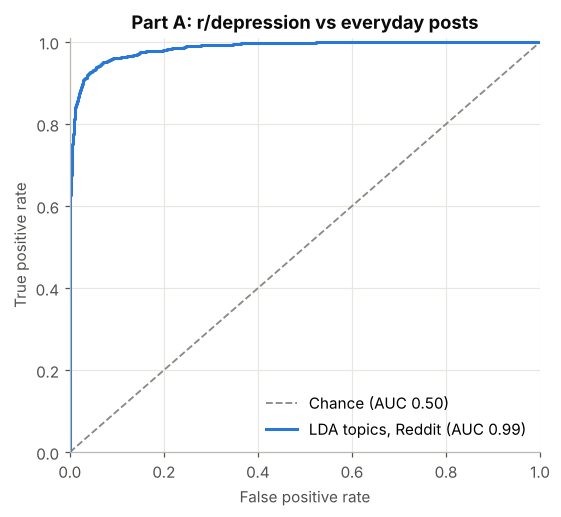

In [6]:
clf = make_pipeline(StandardScaler(), LogisticRegression(max_iter=3000, class_weight="balanced", random_state=SEED))
clf.fit(T_tr, train.label)
p_te = clf.predict_proba(T_te)[:, 1]
auc_a = roc_auc_score(test.label, p_te)
log(f"Part A test AUC = {auc_a:.3f}   (paper, Facebook -> medical records: 0.69)")

fpr, tpr, _ = roc_curve(test.label, p_te)
fig, ax = plt.subplots(figsize=(5.2, 4.8))
ax.plot([0, 1], [0, 1], ls="--", lw=1.2, color=NEUTRAL, label="Chance (AUC 0.50)")
ax.plot(fpr, tpr, lw=2, color=CTRL_COLOR, label=f"LDA topics, Reddit (AUC {auc_a:.2f})")
ax.set(xlim=(0, 1), ylim=(0, 1.01), xlabel="False positive rate", ylabel="True positive rate",
       title="Part A: r/depression vs everyday posts")
ax.legend(frameon=False, loc="lower right")
plt.tight_layout()
save(fig, "partA_roc.png")
plt.show()

### A.2 My twist: which topics predict depression?
For each topic, the model learns a weight. **Positive** weights push a post towards r/depression and **negative** weights push it towards everyday forums. I show the strongest topics with their top words.

I also tag each topic with the **paper's themes** (sadness, loneliness / interpersonal, hostility, rumination / self-focus) when **at least 2** of its top 15 words come from that theme's small seed list (shown in the code). This checks whether Reddit shows the same signs as Facebook.

In [7]:
THEMES = {   # the paper's themes; "never/nothing" = absolutist words (Al-Mosaiwi & Johnstone, 2018)
    "sadness":           {"sad", "sadness", "cry", "crying", "cried", "tears", "hurt", "pain",
                          "empty", "numb", "miserable", "unhappy", "hopeless", "lost"},
    "loneliness / interpersonal": {"alone", "lonely", "loneliness", "nobody", "noone", "isolated",
                          "isolation", "friends", "friend", "talk", "relationship"},
    "hostility":         {"hate", "hated", "angry", "anger", "mad", "rage", "fucking", "fuck", "stupid", "shit"},
    "rumination / self": {"myself", "self", "worthless", "useless", "failure", "pointless", "anymore",
                          "never", "nothing", "thoughts", "overthinking", "mind"},
}

def top_words(k, n=8):
    return [vocab[i] for i in np.argsort(lda.components_[k])[::-1][:n]]

def themes_of(words):
    tags = [t for t, seeds in THEMES.items() if len(seeds & set(words)) >= 2]
    return ", ".join(tags) if tags else "-"

weights = clf[-1].coef_[0]
topics = pd.DataFrame({
    "topic": np.arange(N_TOPICS),
    "weight": weights.round(3),
    "share_of_text": T_tr.mean(axis=0),
    "top_words": [", ".join(top_words(k)) for k in range(N_TOPICS)],
    "paper_theme": [themes_of(top_words(k, 15)) for k in range(N_TOPICS)],
})
topics = topics[topics.share_of_text > 0.5 / N_TOPICS]   # skip near-empty topics
log(f"Part A: {len(topics)} of {N_TOPICS} topics are really used (share > half of average).")
topics.sort_values("weight", ascending=False).to_csv("topics_ranked.csv", index=False)

dep_top = topics[topics.weight > 0].nlargest(12, "weight")
ctrl_top = topics[topics.weight < 0].nsmallest(6, "weight")
pd.set_option("display.max_colwidth", 90)
matched = (dep_top.paper_theme != "-").sum()
log(f"Part A: {matched} of the top {len(dep_top)} depression topics match the paper's themes.")
dep_top[["topic", "weight", "paper_theme", "top_words"]]

02:28:42  Part A: 45 of 50 topics are really used (share > half of average).
02:28:42  Part A: 4 of the top 12 depression topics match the paper's themes.


,topic,weight,paper_theme,top_words
23,23,2.181,"hostility, rumination / self","feel, want, life, myself, hate, nothing, day, fucking"
14,14,1.655,rumination / self,"feel, myself, life, years, never, help, anxiety, self"
8,8,0.730,loneliness / interpersonal,"people, friends, talk, feel, think, say, person, make"
34,34,0.415,-,"love, time, together, wanted, felt, life, ex, loved"
22,22,0.410,-,"today, doctor, went, took, started, days, test, day"
30,30,0.322,-,"want, anyone, feel, sick, way, brain, explain, kinda"
33,33,0.287,-,"post, help, please, questions, question, sub, sorry, ask"
44,44,0.281,-,"school, college, year, high, university, student, classes, years"
19,19,0.251,-,"job, work, time, working, money, months, start, week"
6,6,0.250,-,"anyone, thanks, guys, looking, hey, wondering, good, experience"


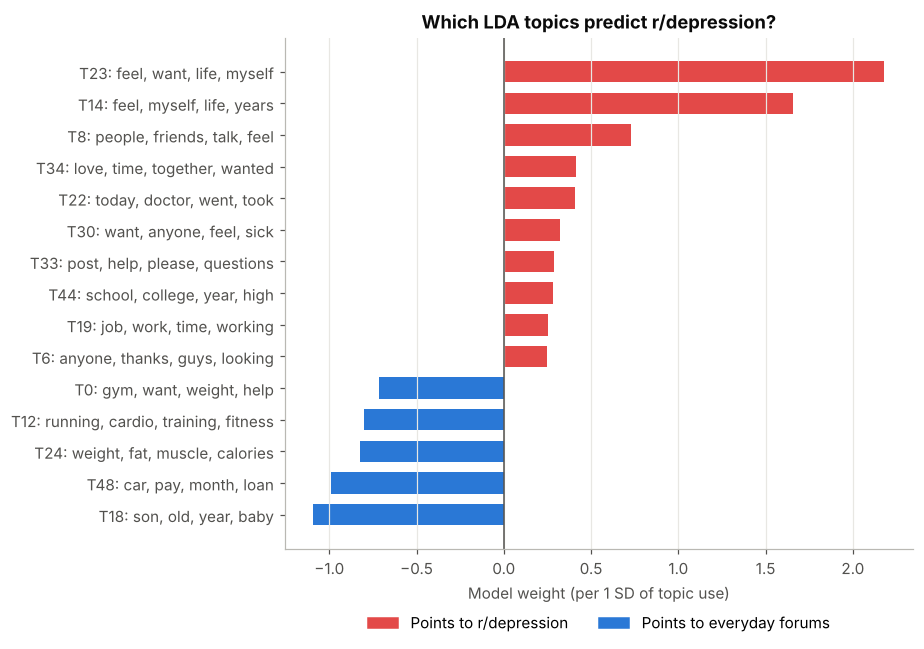

In [8]:
show = pd.concat([dep_top.head(10), ctrl_top.head(5)]).sort_values("weight")
labels = [f"T{t}: {', '.join(w.split(', ')[:4])}" for t, w in zip(show.topic, show.top_words)]
colors = [DEP_COLOR if w > 0 else CTRL_COLOR for w in show.weight]

fig, ax = plt.subplots(figsize=(8.5, 6))
ax.barh(np.arange(len(show)), show.weight, color=colors, height=0.68)
ax.set_yticks(np.arange(len(show)))
ax.set_yticklabels(labels)
ax.axvline(0, color=INK_2, lw=1)
ax.grid(axis="y", visible=False)
ax.set_xlabel("Model weight (per 1 SD of topic use)")
ax.set_title("Which LDA topics predict r/depression?")
ax.legend(handles=[Patch(color=DEP_COLOR, label="Points to r/depression"),
                   Patch(color=CTRL_COLOR, label="Points to everyday forums")],
          frameon=False, loc="upper center", bbox_to_anchor=(0.5, -0.1), ncol=2)
plt.tight_layout()
save(fig, "partA_top_topics.png")
plt.show()

> ✍️ **My reading of Part A**
>
> The model separates the forums almost perfectly (AUC 0.99). This is expected, because the forums talk about different things. The interesting part is **which** topics point to r/depression:
> - The two strongest topics are about the self and life (*feel, want, life, myself, hate, nothing* and *feel, myself, life, years, never, anxiety, self*). This matches the paper's **self-focus / rumination** and **hostility** themes, and includes absolutist words (*nothing, never*).
> - The third is **interpersonal** (*people, friends, talk, feel*), close to the paper's loneliness theme.
> - Other depression topics are about breakups (*love, together, ex*), doctors and feeling sick, school and work.
> - Unlike the paper, **sadness** did not form its own strong topic here: none of the top 12 depression topics was tagged as sadness.

## Part B: everyday posts → later r/depression (closer to the paper)
Part A is easy: the forums talk about different things, so part of the high AUC comes from **topic**, not mood. Part B is harder and closer to the paper's design:

1. Find users who posted in **both** an everyday forum and r/depression.
2. Keep only their everyday posts written **before** their first r/depression post. In the paper, this matches the Facebook posts written before the diagnosis.
3. Controls are everyday users who never posted in r/depression in this data. Each control gets a random "index date" taken from the cases, and only their posts before that date are kept, so both groups come from the same months.
4. Controls are matched **5 to 1** on their main forum and their number of posts.
5. I join each user's posts into one document and run **5-fold cross-validated** LDA + logistic regression. LDA is refit inside each fold, so nothing leaks from the test users.
6. **Check:** I repeat it with plain word features (TF-IDF + logistic regression). If both give the same answer, the result does not depend on the topic model.

Note: because the dataset keeps one post per user in each forum, most users here have only **one** everyday post. The paper had months of Facebook posts per person.

In [9]:
everyday  = raw[raw.label == 0]
first_dep = raw[raw.label == 1].groupby("author")["date"].min().dropna()
dep_users = set(raw.loc[raw.label == 1, "author"])
has_dates = raw["date"].notna().mean() > 0.9

case_posts = everyday[everyday.author.isin(dep_users)]
ctrl_posts = everyday[~everyday.author.isin(dep_users)]

if has_dates:
    case_posts = case_posts[case_posts.date < case_posts.author.map(first_dep)]
    idx_dates = first_dep[first_dep.index.isin(case_posts.author.unique())].to_numpy()
    if len(idx_dates):
        ctrl_users = ctrl_posts.author.unique()
        pseudo = pd.Series(rng.choice(idx_dates, size=len(ctrl_users)), index=ctrl_users)
        ctrl_posts = ctrl_posts[ctrl_posts.date < ctrl_posts.author.map(pseudo)]
    log("Part B: kept only everyday posts written before each user's (index) date.")
else:
    log("Part B: dates missing -> using all everyday posts (no 'before' filter).")

def user_table(posts):
    n = posts.groupby("author").size().rename("n_posts")
    main = (posts.groupby(["author", "subreddit"]).size().rename("k").reset_index()
                 .sort_values("k").drop_duplicates("author", keep="last")
                 .set_index("author")["subreddit"].rename("main_sub"))
    t = pd.concat([n, main], axis=1)
    size_bin = pd.cut(t["n_posts"], [0, 1, 2, 5, np.inf], labels=["1 post", "2 posts", "3-5 posts", "6+ posts"])
    t["stratum"] = t["main_sub"].astype(str) + " | " + size_bin.astype(str)
    return t

cases, ctrls = user_table(case_posts), user_table(ctrl_posts)
picked = []
for stratum, k in cases["stratum"].value_counts().items():
    pool = ctrls.index[(ctrls["stratum"] == stratum).to_numpy()].to_numpy()
    take = min(len(pool), k * CONTROL_RATIO)
    if take:
        picked += list(rng.choice(pool, size=take, replace=False))
picked = pd.Index(picked)

docs_case = case_posts.groupby("author")["text"].apply(" ".join)
docs_ctrl = ctrl_posts[ctrl_posts.author.isin(picked)].groupby("author")["text"].apply(" ".join)
docs = pd.concat([docs_case, docs_ctrl])
y_b = np.r_[np.ones(len(docs_case), dtype=int), np.zeros(len(docs_ctrl), dtype=int)]
log(f"Part B users: {len(docs_case)} later r/depression posters vs {len(docs_ctrl)} matched controls")
if len(cases):
    log(f"Part B: {(cases.n_posts == 1).mean():.0%} of the later r/depression posters have only one everyday post.")

balance = pd.DataFrame({
    "later r/depression (share)": cases["main_sub"].value_counts(normalize=True),
    "matched controls (share)": ctrls.loc[picked, "main_sub"].value_counts(normalize=True),
}).fillna(0).round(2)
balance

02:28:43  Part B: kept only everyday posts written before each user's (index) date.
02:28:43  Part B users: 248 later r/depression posters vs 1240 matched controls
02:28:43  Part B: 96% of the later r/depression posters have only one everyday post.


,later r/depression (share),matched controls (share)
main_sub,,
fitness,0.46,0.46
personalfinance,0.28,0.28
parenting,0.26,0.26


In [10]:
MIN_CASES = 30
auc_b = auc_b_sd = auc_w = auc_w_sd = np.nan
if len(docs_case) < MIN_CASES:
    log(f"Part B skipped: only {len(docs_case)} users (need {MIN_CASES}).")
else:
    cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)
    pipe_b = make_pipeline(
        CountVectorizer(stop_words=STOP, token_pattern=TOKENS, min_df=3, max_df=0.5, max_features=6000),
        LatentDirichletAllocation(n_components=N_TOPICS_B, **LDA_SETTINGS),
        StandardScaler(),
        LogisticRegression(max_iter=3000, class_weight="balanced", random_state=SEED),
    )
    log("Part B: 5-fold cross-validation (LDA topics) ...")
    t0 = time.time()
    aucs = cross_val_score(pipe_b, docs.to_numpy(), y_b, cv=cv, scoring="roc_auc")
    auc_b, auc_b_sd = aucs.mean(), aucs.std()
    log(f"Part B AUC (topics) = {auc_b:.3f} ± {auc_b_sd:.3f} ({time.time() - t0:.0f} s)   | paper: 0.69")

    pipe_w = make_pipeline(
        TfidfVectorizer(stop_words=STOP, token_pattern=TOKENS, min_df=3, max_df=0.5,
                        max_features=20000, sublinear_tf=True),
        LogisticRegression(max_iter=3000, class_weight="balanced", random_state=SEED),
    )
    aucs_w = cross_val_score(pipe_w, docs.to_numpy(), y_b, cv=cv, scoring="roc_auc")
    auc_w, auc_w_sd = aucs_w.mean(), aucs_w.std()
    log(f"Part B check (TF-IDF words) = {auc_w:.3f} ± {auc_w_sd:.3f}")

    # Exploratory only (small sample): which words in everyday posts point to later r/depression?
    pipe_w.fit(docs.to_numpy(), y_b)
    word_w = pd.Series(pipe_w[-1].coef_[0], index=pipe_w[0].get_feature_names_out())
    print("Words pointing to later r/depression:", ", ".join(word_w.nlargest(15).index))
    print("Words pointing to controls:          ", ", ".join(word_w.nsmallest(15).index))

02:28:43  Part B: 5-fold cross-validation (LDA topics) ...


02:28:58  Part B AUC (topics) = 0.522 ± 0.044 (15 s)   | paper: 0.69


02:28:59  Part B check (TF-IDF words) = 0.564 ± 0.028


Words pointing to later r/depression: body, losing, mom, ex, long, dumb, wear, won, results, work, yoga, noob, rich, parents, saying
Words pointing to controls:           lifting, month, baby, buy, lower, bulking, lifts, business, current, shoulder, experience, party, read, especially, ago


## 3. Results at a glance

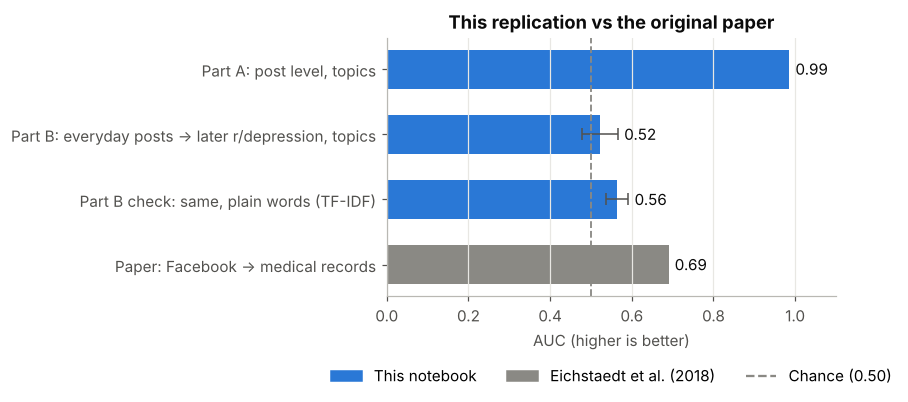

02:28:59  ALL DONE


,result,AUC,sd
0,"Part A: post level, topics",0.986,NaN
1,"Part B: everyday posts -> later r/depression, topics",0.522,0.044
2,"Part B check: same, plain words (TF-IDF)",0.564,0.028
3,Paper: Facebook -> medical records,0.690,NaN


In [11]:
res = pd.DataFrame({
    "result": ["Part A: post level, topics",
               "Part B: everyday posts -> later r/depression, topics",
               "Part B check: same, plain words (TF-IDF)",
               "Paper: Facebook -> medical records"],
    "AUC": [auc_a, auc_b, auc_w, 0.69],
    "sd":  [np.nan, auc_b_sd, auc_w_sd, np.nan],
})
res.round(3).to_csv("results_summary.csv", index=False)

fig, ax = plt.subplots(figsize=(7.8, 3.9))
ax.barh(res.index, res["AUC"].fillna(0), color=[CTRL_COLOR] * 3 + [NEUTRAL], height=0.6)
for i, (v, sd) in enumerate(zip(res["AUC"], res["sd"])):
    if np.isfinite(sd):
        ax.errorbar([v], [i], xerr=[sd], fmt="none", ecolor=INK_2, capsize=4, lw=1)
    end = (0 if np.isnan(v) else v) + (sd if np.isfinite(sd) else 0)
    ax.text(end + 0.015, i, "n/a" if np.isnan(v) else f"{v:.2f}", va="center", color=INK)
ax.axvline(0.5, ls="--", lw=1.2, color=NEUTRAL)
ax.set_yticks(res.index)
ax.set_yticklabels(res["result"])
ax.invert_yaxis()
ax.set_xlim(0, 1.1)
ax.grid(axis="y", visible=False)
ax.set_xlabel("AUC (higher is better)")
ax.set_title("This replication vs the original paper")
ax.legend(handles=[Patch(color=CTRL_COLOR, label="This notebook"),
                   Patch(color=NEUTRAL, label="Eichstaedt et al. (2018)"),
                   Line2D([0], [0], ls="--", color=NEUTRAL, label="Chance (0.50)")],
          frameon=False, loc="upper center", bbox_to_anchor=(0.5, -0.22), ncol=3)
plt.tight_layout()
save(fig, "auc_comparison.png")
plt.show()
log("ALL DONE")
res[["result", "AUC", "sd"]].round(3)

> ✍️ **My summary**
>
> **Part A** reproduces the paper's language themes on Reddit: self-focus / rumination, hostility and interpersonal topics are the strongest signs of r/depression posts.
>
> **Part B**, the harder test that is closer to the paper, mostly did not work: everyday posts written before someone's first r/depression post predicted it only a little above chance (AUC 0.52 with topics, 0.56 with plain words), compared with 0.69 in the paper. Two likely reasons:
> 1. **Too little text per person.** This dataset keeps one post per user in each forum, while the paper used months of Facebook posts per person.
> 2. **Task-focused forums.** People in fitness, money and parenting forums write about the task, not about their mood, unlike open-ended Facebook status updates.
>
> So the signal seems to live in **open-ended, personal writing**, and the amount of text per person matters. A few words in Part B hint at body image, breakups and family, but with 248 users this is only a hint.

## 4. Limits
- Posting in r/depression is **not a diagnosis**. The paper used medical records, which is a much stronger label.
- **Part A** is partly a topic test: forums differ in what they talk about. Removing the words *depression / depressed* reduces this, but does not remove it.
- **Part B** is small (248 users), mostly one post per person, and only sees three everyday forums. Users may talk about their mood in places this data does not cover.
- English-language Reddit users in 2018–2019 are not representative of everyone.

## 5. Next steps
- **More text per person:** repeat Part B with full user histories, which is closer to the paper's design.
- **Time windows:** test 1, 3 and 6 months before the first r/depression post, like the paper's early-warning result.
- **Other cultures:** run the same pipeline on Arabic-language posts to test whether these topics hold across cultures.
- **Modern features:** compare LDA topics with sentence embeddings or LLM-based features.

## References
- Eichstaedt, J. C., et al. (2018). Facebook language predicts depression in medical records. *PNAS*, 115(44), 11203–11208. https://doi.org/10.1073/pnas.1802331115
- Al-Mosaiwi, M., & Johnstone, T. (2018). In an absolute state: Elevated use of absolutist words is a marker specific to anxiety, depression, and suicidal ideation. *Clinical Psychological Science*, 6(4), 529–542.
- Low, D. M., Rumker, L., Talkar, T., Torous, J., Cecchi, G., & Ghosh, S. S. (2020). Natural language processing reveals vulnerable mental health support groups and heightened health anxiety on Reddit during COVID-19: Observational study. *JMIR*, 22(10), e22635. Dataset: https://zenodo.org/records/3941387